# Example 10: Relativitistic Velocity Addition

In this example, we will symbolically regress $f(u,v)=\frac{u+v}{1+uv}$. In relavitity, we know the rapidity trick $f(u,v)={\rm tanh}({\rm arctanh}\ u+{\rm arctanh}\ v)$. Can we rediscover rapidity trick with KAN?

Intialize model and create dataset

In [1]:
import torch
from sympy import nsimplify
from xkan import KANNetwork, create_dataset, fit
from xkan.symbolic import fix_symbolic, suggest_symbolic, symbolic_formula
from xkan.utils import ex_round
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# initialize KAN with G=3
model = KANNetwork([2, 1, 1], grid=10, k=3, device=device)

# create dataset
f = lambda x: (x[:,[0]]+x[:,[1]])/(1+x[:,[0]]*x[:,[1]])
train, test = create_dataset(f, n_var=2, ranges=[-0.9,0.9], device=device)

cuda


Train KAN and plot

In [2]:
history = fit(model, train, test, steps=20)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.0007086172790407844 test RMSE 0.000740187326132945


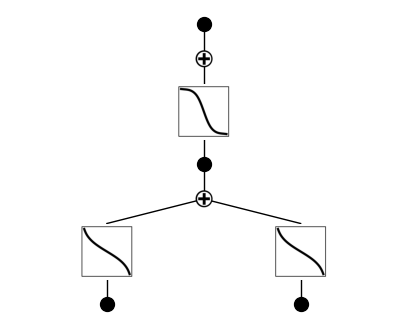

In [3]:
plot(model, train['x'], beta=10);

Retrain the model, the loss remains similar, meaning that the locking does not degrade model behavior, justifying our hypothesis that these two activation functions are the same. Let's now determine what this function is using $\texttt{suggest_symbolic}$

In [4]:
suggest_symbolic(model, 0, 1, 0, train['x'], weight_simple=0.0)

        function        fitting r2           r2 loss        complexity        total loss
         arctanh          0.999999          -16.4168                 4          -16.4168
             tan          0.999839          -12.5153                 3          -12.5153
          arccos          0.998858          -9.76176                 4          -9.76176
          arcsin          0.998858          -9.76161                 4          -9.76161
             exp           0.98265          -5.84808                 2          -5.84808


('arctanh',
 SymbolicFunction(name='arctanh', fn=<function <lambda> at 0x742262c09620>, sympy=<function <lambda> at 0x742262c096c0>, complexity=4, singular=<function <lambda> at 0x742262beac00>),
 np.float64(0.9999985694885254),
 np.int64(4))

We can see that ${\rm arctanh}$ is at the top of the suggestion list! So we can set both to arctanh, retrain the model, and plot it.

In [5]:
# a_range_relative=False: a searched in [-10, 10], as in every pykan release (the default scales that range by the
# inputs' size; here the fits then end less precise)
print('r2 is', float(fix_symbolic(model, 0, 0, 0, 'arctanh', train['x'], a_range_relative=False)))
print('r2 is', float(fix_symbolic(model, 0, 1, 0, 'arctanh', train['x'], a_range_relative=False)))

r2 is 0.9999991655349731
r2 is 0.9999985098838806


In [6]:
history = fit(model, train, test, steps=20, update_grid=False)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.0005433513386737703 test RMSE 0.0005906853377425701


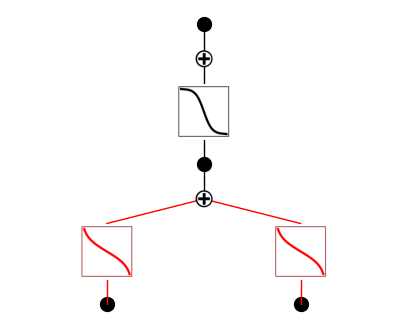

In [7]:
plot(model, train['x'], beta=10);

We will see that ${\rm tanh}$ is at the top of the suggestion list! So we can set it to ${\rm tanh}$, retrain the model to machine precision, plot it and finally get the symbolic formula.

In [8]:
suggest_symbolic(model, 1, 0, 0, train['x'], weight_simple=0.)

        function        fitting r2           r2 loss        complexity        total loss
            tanh          0.999961          -14.3192                 3          -14.3192
          arctan          0.999632          -11.3675                 4          -11.3675
             cos          0.996038          -7.97597                 2          -7.97597
             sin          0.996038          -7.97597                 2          -7.97597
        gaussian          0.993918          -7.35881                 3          -7.35881


('tanh',
 SymbolicFunction(name='tanh', fn=<function <lambda> at 0x742262c08e00>, sympy=<function <lambda> at 0x742262c08ea0>, complexity=3, singular=<function <lambda> at 0x742262c08f40>),
 np.float64(0.9999610781669617),
 np.int64(3))

In [9]:
print('r2 is', float(fix_symbolic(model, 1, 0, 0, 'tanh', train['x'], a_range_relative=False)))

r2 is 0.9684206247329712


In [10]:
history = fit(model, train, test, steps=2000, opt="adam", lr=1e-3, update_grid=False,
              forward_kwargs=dict(singularity_avoiding=True))
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 6.049205837176123e-07 test RMSE 6.281200529195925e-07


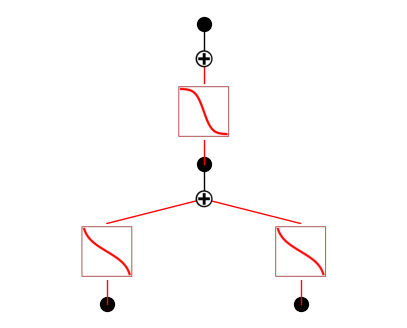

In [11]:
plot(model, train['x']);

In [12]:
formula = symbolic_formula(model)[0][0]
nsimplify(ex_round(formula, 4))

tanh(atanh(x_1) + atanh(x_2))